# Categorical overlap of buried frauds inside $p \le 0.02$

`xgbU_tuned_av2` still scores a block of frauds at $p \le 0.02$. Those are the buried frauds from `mistakes_v1` (no OOF probability lands exactly on $0.02$, so the $\le$ cut and the $<$ cut are the same set). This notebook measures how mixed those frauds are with the clean rows the model also leaves in that band, using only categorical atoms.

Anchors are left out. The seven atoms, in this order, are:

`channel`, `device_type`, `is_new_merchant`, `merchant_category`, `is_alarm`, `card_type`, `auth_method`.

`is_alarm` is the OR of the five alarm flags. Agreement is unweighted: $k$ shared atoms is similarity $k/7$.

The universe for both maps is the OOF region $p \le 0.02$.

1. **Exact overlap (map 1).** For each buried fraud and each $k \in \{3,4,5,6,7\}$, the ids of *clean* rows in the region that agree on exactly $k$ atoms, whichever $k$ those are. Overlaps below 3 are not stored.
2. **Sub-profiles (map 2).** For every subset of at least 2 atoms, and every value combination that occurs, the ids of *all* region rows that carry those values. Atoms outside the subset stay free. Pairwise intersections are in this index; size-1 subsets are not.

A clean row that agrees on all seven atoms is counted only in the map 1 bin $k=7$. That same row still appears in every coarser map 2 sub-profile that contains it.

Map 1 is large on disk (the $k=3$ and $k=4$ lists are most of it). This notebook prints counts, a pairwise census, and the full 7-atom cell of each buried fraud. It is a census of one OOF region, not a fold-safe feature.


In [1]:
from __future__ import annotations

import json
import math
import time
from itertools import combinations
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from tqdm.auto import tqdm

from ccf_ml.cross_validation.alarm import alarm_flag_mask
from ccf_ml.cross_validation.constants import (
    ALARM_FLAG_COLUMNS,
    ID_COLUMN,
    TARGET_COLUMN,
)
from ccf_ml.file_utils import (
    get_script_plot_dir,
    get_script_table_dir,
    get_train_csv_path,
    get_training_exp_dir,
)

MODEL = "xgbU_tuned_av2"
GROUP = "xgbU_tuned_av2_oof_analysis"
NOTEBOOK = "mistakes_v2"
P_MAX = 0.02
MAP1_MIN_OVERLAP = 3
MAP2_MIN_SIZE = 2
DISPLAY_MIN_CELL = 500
ATOM_NAMES = (
    "channel",
    "device_type",
    "is_new_merchant",
    "merchant_category",
    "is_alarm",
    "card_type",
    "auth_method",
)
TRAIN_COLUMNS = (
    ID_COLUMN,
    "channel",
    "device_type",
    "is_new_merchant",
    "merchant_category",
    "card_type",
    "auth_method",
    *ALARM_FLAG_COLUMNS,
)


def encode_atom(*, values: pd.Series, name: str) -> tuple[np.ndarray, tuple]:
    """Return dense uint8 codes and the category tuple those codes index.

    Booleans are always ``(False, True)``. Other atoms are sorted unique values.
    """
    if values.isna().any():
        raise ValueError(f"{name} contains NA")
    if pd.api.types.is_bool_dtype(values):
        codes = values.to_numpy(dtype=bool).astype(np.uint8)
        return codes, (False, True)
    labels = np.unique(values.to_numpy())
    categories = tuple(labels.tolist())
    codes = np.searchsorted(labels, values.to_numpy()).astype(np.uint8)
    return codes, categories


def encode_atoms(
    *,
    frame: pd.DataFrame,
    atom_names: tuple[str, ...],
) -> tuple[np.ndarray, tuple[tuple, ...]]:
    """Column-stack atom codes. Column ``j`` is ``atom_names[j]``."""
    n_rows = len(frame)
    n_atoms = len(atom_names)
    codes = np.empty((n_rows, n_atoms), dtype=np.uint8)
    categories: list[tuple | None] = [None] * n_atoms
    for j, name in enumerate(atom_names):
        if name not in frame.columns:
            raise ValueError(f"frame is missing atom {name}")
        atom_codes, atom_categories = encode_atom(values=frame[name], name=name)
        codes[:, j] = atom_codes
        categories[j] = atom_categories
    if any(item is None for item in categories):
        raise RuntimeError("failed to encode every atom")
    return codes, tuple(categories)


def column_subsets(*, n_atoms: int, min_size: int) -> tuple[tuple[int, ...], ...]:
    """Subsets of ``range(n_atoms)`` with size at least ``min_size``, small first."""
    if min_size < 1 or min_size > n_atoms:
        raise ValueError(f"min_size {min_size} is outside 1..{n_atoms}")
    n_subsets = sum(math.comb(n_atoms, size) for size in range(min_size, n_atoms + 1))
    subsets: list[tuple[int, ...] | None] = [None] * n_subsets
    cursor = 0
    for size in range(min_size, n_atoms + 1):
        for combo in combinations(range(n_atoms), size):
            subsets[cursor] = combo
            cursor += 1
    if cursor != n_subsets or any(item is None for item in subsets):
        raise RuntimeError("failed to enumerate atom subsets")
    return tuple(subsets)


def mask_from_columns(*, columns: tuple[int, ...]) -> int:
    """Bit ``i`` is set when atom ``i`` is in ``columns``."""
    mask = 0
    for column in columns:
        mask |= 1 << column
    return mask


def pack_subset(
    codes: np.ndarray,
    *,
    columns: tuple[int, ...],
    levels: np.ndarray,
) -> np.ndarray:
    """Pack selected atom codes into one int32 key.

    Earlier columns are the low digits. ``levels[c]`` is the radix of atom ``c``.
    """
    if len(columns) == 0:
        raise ValueError("columns is empty")
    packed = np.zeros(codes.shape[0], dtype=np.int64)
    stride = 1
    for column in columns:
        level = int(levels[column])
        if level <= 0 or int(codes[:, column].max()) >= level:
            raise ValueError(f"atom {column} has a code outside its levels")
        packed += codes[:, column].astype(np.int64) * stride
        stride *= level
    if stride > np.iinfo(np.int32).max:
        raise ValueError("packed sub-profile key does not fit in int32")
    return packed.astype(np.int32)


def unpack_keys(
    keys: np.ndarray,
    *,
    columns: tuple[int, ...],
    levels: np.ndarray,
) -> np.ndarray:
    """Invert :func:`pack_subset`. Returns codes shaped ``(n_keys, len(columns))``."""
    remaining = keys.astype(np.int64, copy=True)
    n_keys = keys.shape[0]
    decoded = np.empty((n_keys, len(columns)), dtype=np.int64)
    for j, column in enumerate(columns):
        level = int(levels[column])
        decoded[:, j] = remaining % level
        remaining //= level
    if np.any(remaining != 0):
        raise ValueError("packed key did not unpack cleanly")
    return decoded


def group_packed(
    *,
    packed: np.ndarray,
    row_ids: np.ndarray,
    fraud: np.ndarray,
) -> tuple[np.ndarray, np.ndarray, np.ndarray, np.ndarray]:
    """Group rows that share one packed key.

    Returns strictly increasing keys, CSR offsets, row ids in key order, and
    a fraud count per key. Within a key, ids keep the input order.
    """
    if packed.shape != row_ids.shape or packed.shape != fraud.shape:
        raise ValueError("packed, row_ids, and fraud must share one shape")
    if packed.size == 0:
        raise ValueError("packed is empty")
    order = np.argsort(packed, kind="mergesort")
    packed_sorted = packed[order]
    ids_sorted = row_ids[order]
    fraud_sorted = fraud[order].astype(np.int64)
    change = np.flatnonzero(packed_sorted[1:] != packed_sorted[:-1]) + 1
    n_groups = int(change.size) + 1
    starts = np.empty(n_groups, dtype=np.int64)
    starts[0] = 0
    if n_groups > 1:
        starts[1:] = change
    offsets = np.empty(n_groups + 1, dtype=np.int64)
    offsets[:-1] = starts
    offsets[-1] = packed_sorted.size
    keys = packed_sorted[starts]
    fraud_counts = np.add.reduceat(fraud_sorted, starts).astype(np.int32)
    return keys, offsets, ids_sorted, fraud_counts


def _require_rows(*, codes: np.ndarray, row_ids: np.ndarray, fraud: np.ndarray) -> np.ndarray:
    """Return ``row_ids`` as int32 after checking alignment and range."""
    if codes.ndim != 2:
        raise ValueError(f"codes must be 2-d, got {codes.shape}")
    n_rows = codes.shape[0]
    if row_ids.shape != (n_rows,) or fraud.shape != (n_rows,):
        raise ValueError("row_ids and fraud must align with codes")
    if not np.isin(fraud, (0, 1)).all():
        raise ValueError("fraud must be 0/1")
    if n_rows == 0:
        raise ValueError("region is empty")
    if int(row_ids.min()) < 0 or int(row_ids.max()) > np.iinfo(np.int32).max:
        raise ValueError("row ids must be non-negative and fit in int32")
    if np.unique(row_ids).shape[0] != n_rows:
        raise ValueError("row ids are not unique")
    return row_ids.astype(np.int32)


def _close_memmap(store: np.memmap) -> None:
    """Flush a memmap and close the underlying file."""
    store.flush()
    mapped = getattr(store, "_mmap", None)
    if mapped is not None:
        mapped.close()


def _directory_bytes(path: Path) -> int:
    """Total size of files under ``path``."""
    total = 0
    for file in path.rglob("*"):
        if file.is_file():
            total += file.stat().st_size
    return total


def exact_clean_ids(*, table_dir: Path, buried_id: int, overlap: int) -> np.ndarray:
    """Clean region ids that agree with ``buried_id`` on exactly ``overlap`` atoms.

    The id file is a raw int32 memmap. Its length is the last CSR offset.
    """
    buried_ids = np.load(table_dir / "map1" / "buried_ids.npy")
    pos = int(np.searchsorted(buried_ids, np.int32(buried_id)))
    if pos >= buried_ids.shape[0] or int(buried_ids[pos]) != int(buried_id):
        raise KeyError(f"buried id {buried_id} is not in map 1")
    offsets = np.load(table_dir / "map1" / f"k{overlap}_offsets.npy")
    start = int(offsets[pos])
    end = int(offsets[pos + 1])
    n_ids = int(offsets[-1])
    if end < start or n_ids < end:
        raise ValueError(f"overlap {overlap} offsets are not a valid CSR range")
    path = table_dir / "map1" / f"k{overlap}_clean_ids.i32"
    if path.stat().st_size != n_ids * np.dtype(np.int32).itemsize:
        raise ValueError(f"{path.name} size does not match its offsets")
    if start == end:
        return np.empty(0, dtype=np.int32)
    store = np.memmap(path, dtype=np.int32, mode="r", shape=(n_ids,))
    chosen = np.array(store[start:end], copy=True)
    _close_memmap(store)
    return chosen


def subprofile_row_ids(
    *,
    table_dir: Path,
    atom_names: tuple[str, ...],
    categories: tuple[tuple, ...],
    values: dict[str, object],
) -> np.ndarray:
    """Ids of region rows that match ``values`` on the named atoms.

    Atoms omitted from ``values`` stay free. ``values`` must name at least two atoms.
    """
    unknown = [name for name in values if name not in atom_names]
    if unknown:
        raise KeyError(f"unknown atoms: {unknown}")
    if len(values) < 2:
        raise ValueError("a sub-profile needs at least 2 atoms")
    columns = tuple(index for index, name in enumerate(atom_names) if name in values)
    code_row = np.zeros((1, len(atom_names)), dtype=np.uint8)
    for column in columns:
        name = atom_names[column]
        code_row[0, column] = _category_code(
            categories=categories[column],
            value=values[name],
            name=name,
        )
    levels = np.array([len(item) for item in categories], dtype=np.int64)
    key = int(pack_subset(code_row, columns=columns, levels=levels)[0])
    mask = mask_from_columns(columns=columns)
    folder = table_dir / "map2" / f"m{mask:03d}"
    keys = np.load(folder / "keys.npy")
    offsets = np.load(folder / "offsets.npy")
    pos = int(np.searchsorted(keys, np.int32(key)))
    if pos >= keys.shape[0] or int(keys[pos]) != key:
        return np.empty(0, dtype=np.int32)
    start = int(offsets[pos])
    end = int(offsets[pos + 1])
    stored_ids = np.load(folder / "row_ids.npy", mmap_mode="r")
    return np.array(stored_ids[start:end], copy=True)


def _category_code(*, categories: tuple, value: object, name: str) -> int:
    """Index of ``value`` in one atom's category tuple."""
    for index, category in enumerate(categories):
        if category == value:
            return index
    raise KeyError(f"{name} has no category {value!r}")


def build_exact_clean_overlap(
    *,
    codes: np.ndarray,
    row_ids: np.ndarray,
    fraud: np.ndarray,
    destination: Path,
    min_overlap: int,
) -> np.ndarray:
    """Write map 1 and return clean-neighbor counts shaped ``(n_buried, n_k)``.

    Column ``j`` is overlap ``min_overlap + j``. Buried ids and counts are ``.npy``.
    Clean ids are raw int32 memmaps addressed by CSR offsets.
    """
    stored_ids = _require_rows(codes=codes, row_ids=row_ids, fraud=fraud)
    n_atoms = codes.shape[1]
    if min_overlap < 1 or min_overlap > n_atoms:
        raise ValueError(f"min_overlap {min_overlap} is outside 1..{n_atoms}")
    overlaps = tuple(range(min_overlap, n_atoms + 1))
    n_overlaps = len(overlaps)
    buried_pos = np.flatnonzero(fraud == 1)
    clean_pos = np.flatnonzero(fraud == 0)
    n_buried = int(buried_pos.shape[0])
    if n_buried == 0:
        raise ValueError("region has no buried frauds")
    clean_codes = np.ascontiguousarray(codes[clean_pos])
    clean_ids = stored_ids[clean_pos]
    counts = np.zeros((n_buried, n_overlaps), dtype=np.int64)
    for i in tqdm(range(n_buried), desc="map1 counts"):
        agree = (clean_codes == codes[buried_pos[i]]).sum(axis=1)
        buckets = np.bincount(agree, minlength=n_atoms + 1)
        counts[i] = buckets[min_overlap:]
    offsets = np.zeros((n_overlaps, n_buried + 1), dtype=np.int64)
    offsets[:, 1:] = np.cumsum(counts, axis=0).T
    destination.mkdir(parents=True, exist_ok=True)
    stores: list = [None] * n_overlaps
    try:
        for j, overlap in enumerate(overlaps):
            np.save(destination / f"k{overlap}_offsets.npy", offsets[j])
            n_ids = int(offsets[j, -1])
            path = destination / f"k{overlap}_clean_ids.i32"
            if n_ids == 0:
                path.write_bytes(b"")
                continue
            stores[j] = np.memmap(path, dtype=np.int32, mode="w+", shape=(n_ids,))
        cursors = np.zeros(n_overlaps, dtype=np.int64)
        for i in tqdm(range(n_buried), desc="map1 ids"):
            agree = (clean_codes == codes[buried_pos[i]]).sum(axis=1)
            keep = np.flatnonzero(agree >= min_overlap)
            kept_agree = agree[keep]
            kept_ids = clean_ids[keep]
            for j, overlap in enumerate(overlaps):
                chosen = kept_ids[kept_agree == overlap]
                start = int(cursors[j])
                if start != int(offsets[j, i]):
                    raise ValueError("map 1 write cursor diverged from offsets")
                end = start + int(chosen.shape[0])
                store = stores[j]
                if store is not None and end > start:
                    store[start:end] = chosen
                cursors[j] = end
        if not np.array_equal(cursors, offsets[:, -1]):
            raise ValueError("map 1 id cursor did not land on the counted totals")
    finally:
        for store in stores:
            if store is not None:
                _close_memmap(store)
    np.save(destination / "buried_ids.npy", stored_ids[buried_pos])
    np.save(destination / "counts.npy", counts)
    np.save(destination / "overlaps.npy", np.array(overlaps, dtype=np.int64))
    return counts


def build_subprofile_index(
    *,
    codes: np.ndarray,
    row_ids: np.ndarray,
    fraud: np.ndarray,
    atom_names: tuple[str, ...],
    categories: tuple[tuple, ...],
    destination: Path,
    min_size: int,
) -> pd.DataFrame:
    """Write map 2 and return one catalog row per stored subset.

    Folder ``m{mask:03d}`` holds packed keys, CSR offsets, row ids, fraud counts,
    and ``atoms.json`` in pack order. Bit ``i`` of the mask is atom ``i``.
    """
    stored_ids = _require_rows(codes=codes, row_ids=row_ids, fraud=fraud)
    n_atoms = codes.shape[1]
    if len(atom_names) != n_atoms or len(categories) != n_atoms:
        raise ValueError("atom_names and categories must match the code columns")
    levels = np.array([len(item) for item in categories], dtype=np.int64)
    if np.any(levels <= 0):
        raise ValueError("every atom needs at least one category")
    n_fraud = int(fraud.sum(dtype=np.int64))
    subsets = column_subsets(n_atoms=n_atoms, min_size=min_size)
    n_subsets = len(subsets)
    catalog: list[dict | None] = [None] * n_subsets
    destination.mkdir(parents=True, exist_ok=True)
    for index, subset in enumerate(tqdm(subsets, desc="map2 subsets")):
        packed = pack_subset(codes, columns=subset, levels=levels)
        keys, offsets, ids_sorted, fraud_counts = group_packed(
            packed=packed,
            row_ids=stored_ids,
            fraud=fraud,
        )
        if int(fraud_counts.sum(dtype=np.int64)) != n_fraud:
            raise ValueError("map 2 fraud counts do not cover every fraud")
        if int(offsets[-1]) != stored_ids.shape[0]:
            raise ValueError("map 2 row ids do not cover the region")
        mask = mask_from_columns(columns=subset)
        folder = destination / f"m{mask:03d}"
        folder.mkdir(parents=True, exist_ok=True)
        atom_list = [atom_names[column] for column in subset]
        np.save(folder / "keys.npy", keys)
        np.save(folder / "offsets.npy", offsets)
        np.save(folder / "fraud_counts.npy", fraud_counts)
        np.save(folder / "row_ids.npy", ids_sorted)
        (folder / "atoms.json").write_text(json.dumps(atom_list), encoding="utf-8")
        catalog[index] = {
            "mask": mask,
            "size": len(subset),
            "atoms": "|".join(atom_list),
            "n_profiles": int(keys.shape[0]),
            "n_rows": int(offsets[-1]),
        }
    if any(item is None for item in catalog):
        raise RuntimeError("failed to catalog every sub-profile subset")
    catalog_frame = pd.DataFrame(catalog)
    catalog_frame.to_csv(destination / "catalog.csv", index=False)
    return catalog_frame


def overlap_count_summary(*, counts: np.ndarray, overlaps: tuple[int, ...]) -> pd.DataFrame:
    """One row per exact overlap: clean-neighbor counts across buried frauds."""
    if counts.shape[1] != len(overlaps):
        raise ValueError("counts columns do not match overlaps")
    n_overlaps = len(overlaps)
    rows: list[dict | None] = [None] * n_overlaps
    for j, overlap in enumerate(overlaps):
        column = counts[:, j]
        rows[j] = {
            "k": overlap,
            "pairs": int(column.sum()),
            "median": float(np.median(column)),
            "p10": float(np.quantile(column, 0.10)),
            "p90": float(np.quantile(column, 0.90)),
            "min": int(column.min()),
            "max": int(column.max()),
        }
    if any(item is None for item in rows):
        raise RuntimeError("failed to summarize overlaps")
    return pd.DataFrame(rows)


def _json_category(value: object) -> object:
    """JSON value for one category label."""
    if isinstance(value, (bool, np.bool_)):
        return bool(value)
    if isinstance(value, (np.integer, int)):
        return int(value)
    return str(value)


def save_codebooks(
    *,
    path: Path,
    atom_names: tuple[str, ...],
    categories: tuple[tuple, ...],
) -> None:
    """Write atom order and category labels so packed keys can be decoded later."""
    n_atoms = len(atom_names)
    atoms: list[dict | None] = [None] * n_atoms
    for index, name in enumerate(atom_names):
        labels = categories[index]
        encoded: list[object | None] = [None] * len(labels)
        for label_index, label in enumerate(labels):
            encoded[label_index] = _json_category(label)
        atoms[index] = {"name": name, "categories": encoded}
    if any(item is None for item in atoms):
        raise RuntimeError("failed to encode codebooks")
    path.write_text(json.dumps({"atoms": atoms}, indent=2), encoding="utf-8")


def check_overlap_contracts() -> None:
    """Build both maps on a hand-checked toy region and compare the id lists."""
    codes = np.array(
        [
            [0, 0, 0],
            [0, 0, 0],
            [0, 0, 1],
            [0, 1, 1],
            [1, 1, 1],
            [0, 0, 0],
            [0, 1, 0],
            [1, 0, 0],
        ],
        dtype=np.uint8,
    )
    row_ids = np.arange(codes.shape[0], dtype=np.int32)
    fraud = np.array([1, 0, 0, 0, 0, 1, 0, 0], dtype=np.uint8)
    atom_names = ("a", "b", "c")
    categories = ((0, 1), (0, 1), (0, 1))
    import tempfile

    with tempfile.TemporaryDirectory(prefix="mistakes_v2_toy_") as folder:
        root = Path(folder)
        build_exact_clean_overlap(
            codes=codes,
            row_ids=row_ids,
            fraud=fraud,
            destination=root / "map1",
            min_overlap=2,
        )
        build_subprofile_index(
            codes=codes,
            row_ids=row_ids,
            fraud=fraud,
            atom_names=atom_names,
            categories=categories,
            destination=root / "map2",
            min_size=2,
        )
        got_k2 = exact_clean_ids(table_dir=root, buried_id=0, overlap=2)
        got_k3 = exact_clean_ids(table_dir=root, buried_id=0, overlap=3)
        if not np.array_equal(got_k2, np.array([2, 6, 7], dtype=np.int32)):
            raise AssertionError(f"toy k=2 ids were {got_k2.tolist()}")
        if not np.array_equal(got_k3, np.array([1], dtype=np.int32)):
            raise AssertionError(f"toy k=3 ids were {got_k3.tolist()}")
        same_profile = exact_clean_ids(table_dir=root, buried_id=5, overlap=3)
        if not np.array_equal(same_profile, got_k3):
            raise AssertionError("twin buried frauds did not share the k=3 clean list")
        partial = subprofile_row_ids(
            table_dir=root,
            atom_names=atom_names,
            categories=categories,
            values={"a": 0, "b": 0},
        )
        if not np.array_equal(np.sort(partial), np.array([0, 1, 2, 5], dtype=np.int32)):
            raise AssertionError(f"toy pair profile ids were {partial.tolist()}")
    print("toy overlap contracts: ok")


## Contracts on a toy region

Eight rows, three atoms. Two frauds share the profile `(0,0,0)`. The clean lists below are small enough to check by hand before the real region is written.


In [ ]:
check_overlap_contracts()

toy overlap contracts: ok


## Region

Train rows joined to `xgbU_tuned_av2` OOF on `id`, restricted to $p \le 0.02$, sorted by `id`. Buried rows are the frauds inside that cut.


In [5]:
oof = pd.read_csv(get_training_exp_dir(MODEL) / "oof.csv")
train = pd.read_csv(get_train_csv_path(), usecols=list(TRAIN_COLUMNS))
frame = oof.merge(train, on=ID_COLUMN, how="left", validate="one_to_one", indicator=True)
if not bool((frame["_merge"] == "both").all()):
    raise ValueError("oof ids missing from train")
frame = frame.drop(columns="_merge")
frame["is_alarm"] = alarm_flag_mask(frame, columns=ALARM_FLAG_COLUMNS).to_numpy(dtype=bool)
frame = frame.drop(columns=list(ALARM_FLAG_COLUMNS))

n_rows_all = int(len(frame))
n_fraud_all = int(frame[TARGET_COLUMN].sum())
region = (
    frame.loc[frame["y_prob"] <= P_MAX, [ID_COLUMN, TARGET_COLUMN, "y_prob", *ATOM_NAMES]]
    .sort_values(ID_COLUMN)
    .reset_index(drop=True)
)
codes, categories = encode_atoms(frame=region, atom_names=ATOM_NAMES)
row_ids = region[ID_COLUMN].to_numpy(dtype=np.int64)
fraud = region[TARGET_COLUMN].to_numpy(dtype=np.uint8)
p_region = region["y_prob"].to_numpy(dtype=np.float64)
levels = np.array([len(item) for item in categories], dtype=np.int64)

table_dir = get_script_table_dir(NOTEBOOK, group=GROUP)
plot_dir = get_script_plot_dir(NOTEBOOK, section="m", group=GROUP)
region.to_parquet(table_dir / "region.parquet", index=False)
save_codebooks(path=table_dir / "codebooks.json", atom_names=ATOM_NAMES, categories=categories)

n_region = int(len(region))
n_buried = int(fraud.sum(dtype=np.int64))
n_clean = n_region - n_buried
region_rate = n_buried / n_region
level_table = pd.DataFrame(
    {
        "atom": ATOM_NAMES,
        "n_levels": [len(item) for item in categories],
        "categories": [list(item) for item in categories],
    }
)
display(level_table)
print(
    f"model {MODEL} | all rows {n_rows_all} | all frauds {n_fraud_all} | "
    f"region p <= {P_MAX}: {n_region} | buried {n_buried} "
    f"({n_buried / n_fraud_all:.3f} of frauds) | cleans {n_clean} | "
    f"region fraud rate {region_rate:.6f}"
)
print("tables ->", table_dir)
print("plots  ->", plot_dir)


model xgbU_tuned_av2 | all rows 699960 | all frauds 11689 | region p <= 0.02: 626860 | buried 1941 (0.166 of frauds) | cleans 624919 | region fraud rate 0.003096
tables -> C:\Users\bouab\ayhem-personal\DEV\ML\DL_projects\kaggle_comps\CreditCardFraud\storage\artifacts\xgbU_tuned_av2_oof_analysis\mistakes_v2\tables
plots  -> C:\Users\bouab\ayhem-personal\DEV\ML\DL_projects\kaggle_comps\CreditCardFraud\storage\artifacts\xgbU_tuned_av2_oof_analysis\mistakes_v2\plots\m


,atom,n_levels,categories
0,channel,5,"[ATM, Contactless, In-App, Online, POS]"
1,device_type,8,"[ATM Machine, Android Phone, Mac, POS Terminal, Smart Watch, Tablet, Windows PC, iPhone]"
2,is_new_merchant,2,"[False, True]"
3,merchant_category,12,"[Crypto Exchange, Electronics, Fuel, Gaming, Gift Cards, Groceries, Healthcare, Online Retail, Restaurants, Streaming, Travel, Utilities]"
4,is_alarm,2,"[False, True]"
5,card_type,5,"[Amex, Discover, Mastercard, RuPay, Visa]"
6,auth_method,5,"[3D Secure, Biometric, No Authentication, OTP, PIN]"


## Map 1 — exact overlap

`map1/counts.npy` is `(n_buried, 5)` in the same order as `buried_ids.npy`. Column order is $k = 3,4,5,6,7$. `k{k}_offsets.npy` indexes the raw int32 file `k{k}_clean_ids.i32`.


In [7]:
started = time.perf_counter()
counts = build_exact_clean_overlap(
    codes=codes,
    row_ids=row_ids,
    fraud=fraud,
    destination=table_dir / "map1",
    min_overlap=MAP1_MIN_OVERLAP,
)
elapsed = time.perf_counter() - started
map1_bytes = _directory_bytes(table_dir / "map1")
print(f"map 1 written in {elapsed:.1f}s | {map1_bytes / (1024 ** 3):.2f} GiB")


map 1 written in 72.5s | 2.62 GiB


median clean rows at k >= 3: 400456 of 624919 cleans (0.641)


,k,pairs,median,p10,p90,min,max
0,3,410523648,230701.0,151226.0,249778.0,17582,265885
1,4,222423336,122956.0,41262.0,176047.0,1665,197523
2,5,62149106,27822.0,5261.0,65813.0,102,98335
3,6,8535686,2709.0,278.0,11241.0,3,23744
4,7,447548,80.0,5.0,672.0,0,2266


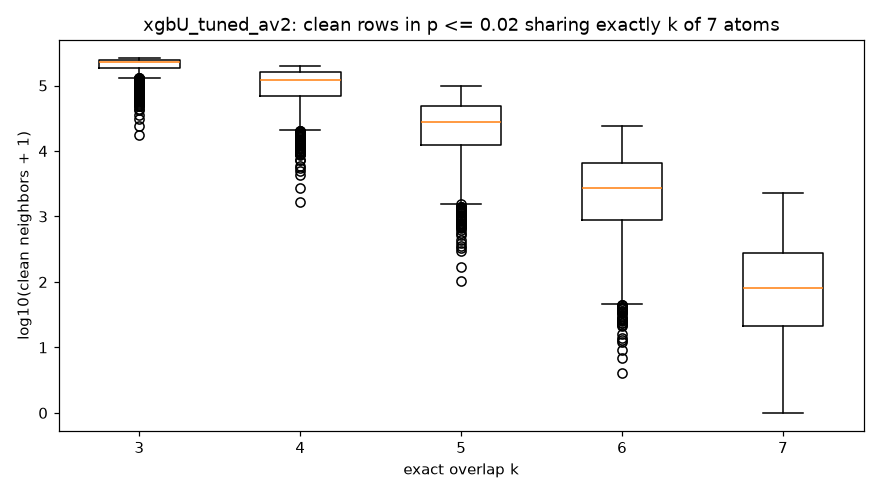

In [8]:
overlaps = tuple(int(value) for value in np.load(table_dir / "map1" / "overlaps.npy"))
counts = np.load(table_dir / "map1" / "counts.npy")
summary = overlap_count_summary(counts=counts, overlaps=overlaps)
summary.to_csv(table_dir / "map1_overlap_summary.csv", index=False)
display(summary)

covered = counts.sum(axis=1)
print(
    f"median clean rows at k >= {MAP1_MIN_OVERLAP}: {float(np.median(covered)):.0f} "
    f"of {n_clean} cleans ({float(np.median(covered)) / n_clean:.3f})"
)

logged = [None] * len(overlaps)
for j, overlap in enumerate(overlaps):
    logged[j] = np.log10(counts[:, j] + 1.0)
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.boxplot(logged, tick_labels=[str(overlap) for overlap in overlaps])
ax.set_xlabel("exact overlap k")
ax.set_ylabel("log10(clean neighbors + 1)")
ax.set_title(
    f"{MODEL}: clean rows in p <= {P_MAX} sharing exactly k of {len(ATOM_NAMES)} atoms"
)
fig.tight_layout()
fig.savefig(plot_dir / "map1_clean_overlap_counts.png", dpi=110)
plt.show()


## Map 2 — sub-profiles of size at least 2

Each observed value combination is one key. The id list is every region row with those values, fraud and clean. `fraud_counts.npy` is aligned with `keys.npy` and includes the buried frauds in the cell.


In [10]:
started = time.perf_counter()
catalog = build_subprofile_index(
    codes=codes,
    row_ids=row_ids,
    fraud=fraud,
    atom_names=ATOM_NAMES,
    categories=categories,
    destination=table_dir / "map2",
    min_size=MAP2_MIN_SIZE,
)
elapsed = time.perf_counter() - started
map2_bytes = _directory_bytes(table_dir / "map2")
print(f"map 2 written in {elapsed:.1f}s | {map2_bytes / (1024 ** 3):.2f} GiB")
display(catalog.groupby("size", as_index=False)["n_profiles"].sum())


map 2 written in 7.6s | 0.28 GiB


,size,n_profiles
0,2,615
1,3,5088
2,4,23463
3,5,56279
4,6,61171
5,7,23448


## Census

Pair cells are the size-2 slice of map 2. Lift is the cell fraud rate divided by the region fraud rate. The display floor of 500 rows keeps a handful of tiny cells from topping the lift list; the full pair table is written beside the maps.

The full-profile table is the size-7 key of each buried fraud. Its clean count has to match map 1 at $k=7$: those are the same rows. The lowest-scored buried fraud is then checked, id for id, against a direct column comparison.


pair cells 615 | with n >= 500: 586 | region rate 0.003096
highest lift
largest share of buried frauds
share of buried whose full-profile rate exceeds p: 0.719
share of buried whose full-profile rate exceeds 2p: 0.552
share of buried who share the full profile with another fraud: 0.331
lowest-p buried id 226293 | p 0.00011635
    id   y_prob  n_rows  n_fraud  n_other_fraud  n_clean  fraud_rate
226293 0.000116     218        1              0      217    0.004587
lowest-p id lists match a direct comparison at k = [3, 4, 5, 6, 7]
mistakes_v2 complete


,atom_a,value_a,atom_b,value_b,n,n_fraud,fraud_rate,lift_vs_region,share_of_buried
0,is_new_merchant,True,merchant_category,Gaming,1496,23,0.015374,4.965252,0.011850
1,merchant_category,Gaming,is_alarm,True,543,8,0.014733,4.758118,0.004122
2,merchant_category,Crypto Exchange,auth_method,PIN,894,13,0.014541,4.696246,0.006698
3,device_type,iPhone,merchant_category,Crypto Exchange,723,10,0.013831,4.466905,0.005152
4,is_new_merchant,True,auth_method,No Authentication,4254,51,0.011989,3.871843,0.026275
5,merchant_category,Healthcare,is_alarm,True,1791,21,0.011725,3.786768,0.010819
6,is_new_merchant,True,is_alarm,True,3236,37,0.011434,3.692651,0.019062
7,is_alarm,True,card_type,RuPay,1691,19,0.011236,3.628733,0.009789
8,merchant_category,Electronics,is_alarm,True,1640,18,0.010976,3.544653,0.009274
9,is_alarm,True,auth_method,No Authentication,1601,17,0.010618,3.429277,0.008758


,atom_a,value_a,atom_b,value_b,n,n_fraud,fraud_rate,lift_vs_region,share_of_buried
0,is_new_merchant,False,is_alarm,False,517653,1282,0.002477,0.799824,0.660484
1,is_alarm,False,card_type,Visa,292358,806,0.002757,0.890359,0.415250
2,is_new_merchant,False,card_type,Visa,269273,725,0.002692,0.869541,0.373519
3,is_alarm,False,card_type,Mastercard,216538,627,0.002896,0.935144,0.323029
4,channel,POS,is_alarm,False,177561,584,0.003289,1.062210,0.300876
5,channel,Online,is_alarm,False,228338,565,0.002474,0.799126,0.291087
6,device_type,Android Phone,is_alarm,False,202131,558,0.002761,0.891551,0.287481
7,is_new_merchant,False,card_type,Mastercard,199980,554,0.002770,0.894681,0.285420
8,is_alarm,False,auth_method,3D Secure,179099,531,0.002965,0.957517,0.273570
9,channel,Online,is_new_merchant,False,212775,521,0.002449,0.790792,0.268418


,n_rows,n_clean,n_other_fraud,fraud_rate,y_prob
count,1941.000000,1941.000000,1941.000000,1941.000000,1941.000000
mean,232.178774,230.575992,0.602782,0.079068,0.008778
std,360.943846,360.246722,1.128073,0.185200,0.005545
min,1.000000,0.000000,0.000000,0.000566,0.000116
25%,21.000000,20.000000,0.000000,0.005917,0.003848
50%,81.000000,80.000000,0.000000,0.015873,0.007985
75%,274.000000,272.000000,1.000000,0.054054,0.013309
max,2270.000000,2266.000000,6.000000,1.000000,0.019989


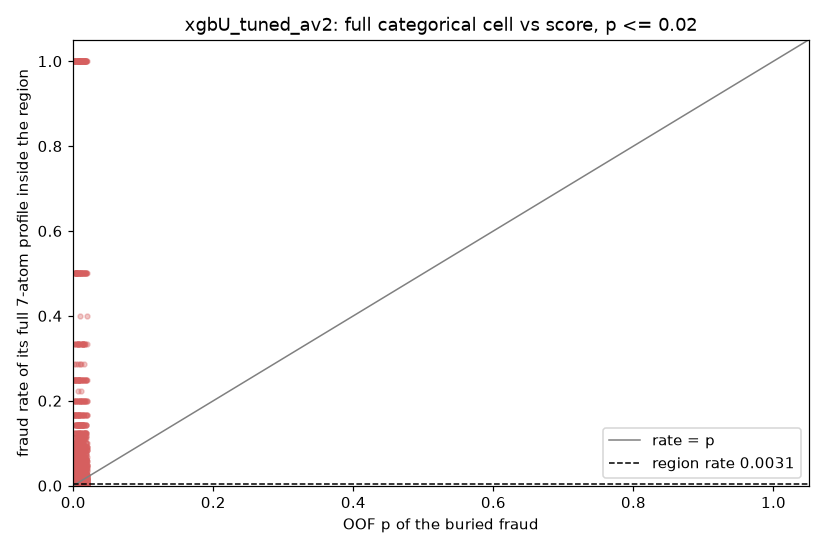

,value
channel,Online
device_type,POS Terminal
is_new_merchant,False
merchant_category,Online Retail
is_alarm,False
card_type,Mastercard
auth_method,No Authentication


,atom_a,value_a,atom_b,value_b,n,n_fraud,fraud_rate,lift_vs_region,share_of_buried
0,channel,Online,device_type,POS Terminal,40077,122,0.003044,0.983127,0.062854
1,channel,Online,is_new_merchant,False,212775,521,0.002449,0.790792,0.268418
2,channel,Online,merchant_category,Online Retail,55251,150,0.002715,0.876791,0.077280
3,channel,Online,is_alarm,False,228338,565,0.002474,0.799126,0.291087
4,channel,Online,card_type,Mastercard,88215,255,0.002891,0.933561,0.131376
5,channel,Online,auth_method,No Authentication,17330,98,0.005655,1.826302,0.050489
6,device_type,POS Terminal,is_new_merchant,False,88621,242,0.002731,0.881909,0.124678
7,device_type,POS Terminal,merchant_category,Online Retail,23581,63,0.002672,0.862826,0.032457
8,device_type,POS Terminal,is_alarm,False,95833,273,0.002849,0.920010,0.140649
9,device_type,POS Terminal,card_type,Mastercard,37277,113,0.003031,0.979000,0.058217


In [12]:
def pair_census(
    *,
    table_dir: Path,
    atom_names: tuple[str, ...],
    categories: tuple[tuple, ...],
    levels: np.ndarray,
    n_buried: int,
    region_rate: float,
) -> pd.DataFrame:
    """Every observed size-2 profile in map 2, with rate and lift inside the region."""
    n_pairs = math.comb(len(atom_names), 2)
    pair_subsets = column_subsets(n_atoms=len(atom_names), min_size=2)[:n_pairs]
    frames: list[pd.DataFrame | None] = [None] * n_pairs
    for index, subset in enumerate(pair_subsets):
        if len(subset) != 2:
            raise RuntimeError("size-2 subsets were not the first block")
        mask = mask_from_columns(columns=subset)
        folder = table_dir / "map2" / f"m{mask:03d}"
        keys = np.load(folder / "keys.npy")
        offsets = np.load(folder / "offsets.npy")
        fraud_counts = np.load(folder / "fraud_counts.npy")
        decoded = unpack_keys(keys, columns=subset, levels=levels)
        n_keys = int(keys.shape[0])
        value_a: list[object | None] = [None] * n_keys
        value_b: list[object | None] = [None] * n_keys
        cats_a = categories[subset[0]]
        cats_b = categories[subset[1]]
        for key_index in range(n_keys):
            value_a[key_index] = cats_a[int(decoded[key_index, 0])]
            value_b[key_index] = cats_b[int(decoded[key_index, 1])]
        if any(item is None for item in value_a) or any(item is None for item in value_b):
            raise RuntimeError("failed to decode a pair profile")
        n_rows = np.diff(offsets)
        rate = fraud_counts / n_rows
        frames[index] = pd.DataFrame(
            {
                "atom_a": atom_names[subset[0]],
                "value_a": value_a,
                "atom_b": atom_names[subset[1]],
                "value_b": value_b,
                "n": n_rows.astype(np.int64),
                "n_fraud": fraud_counts.astype(np.int64),
                "fraud_rate": rate,
                "lift_vs_region": rate / region_rate,
                "share_of_buried": fraud_counts / n_buried,
            }
        )
    if any(item is None for item in frames):
        raise RuntimeError("failed to read every pair subset")
    return pd.concat(frames, ignore_index=True)


def full_profiles_of_buried(
    *,
    table_dir: Path,
    codes: np.ndarray,
    row_ids: np.ndarray,
    fraud: np.ndarray,
    p_region: np.ndarray,
    levels: np.ndarray,
    counts: np.ndarray,
) -> pd.DataFrame:
    """Size-7 cell of each buried fraud, checked against map 1 at k = 7."""
    buried_pos = np.flatnonzero(fraud == 1)
    n_atoms = codes.shape[1]
    columns = tuple(range(n_atoms))
    mask = mask_from_columns(columns=columns)
    folder = table_dir / "map2" / f"m{mask:03d}"
    keys = np.load(folder / "keys.npy")
    offsets = np.load(folder / "offsets.npy")
    fraud_counts = np.load(folder / "fraud_counts.npy")
    packed = pack_subset(codes[buried_pos], columns=columns, levels=levels)
    pos = np.searchsorted(keys, packed)
    if int(pos.max()) >= keys.shape[0] or not np.array_equal(keys[pos], packed):
        raise ValueError("a buried fraud is missing from the size-7 index")
    n_rows = np.diff(offsets)[pos]
    n_fraud_cell = fraud_counts[pos].astype(np.int64)
    n_clean_cell = n_rows - n_fraud_cell
    if not np.array_equal(n_clean_cell, counts[:, -1]):
        raise ValueError("map 1 k=7 clean counts do not match the full-profile index")
    return pd.DataFrame(
        {
            "id": row_ids[buried_pos],
            "y_prob": p_region[buried_pos],
            "n_rows": n_rows,
            "n_fraud": n_fraud_cell,
            "n_other_fraud": n_fraud_cell - 1,
            "n_clean": n_clean_cell,
            "fraud_rate": n_fraud_cell / n_rows,
        }
    )


def buried_pair_rows(
    *,
    pairs: pd.DataFrame,
    profile: pd.Series,
    atom_names: tuple[str, ...],
) -> pd.DataFrame:
    """The one size-2 cell per atom pair that contains this buried row."""
    n_pairs = math.comb(len(atom_names), 2)
    subsets = column_subsets(n_atoms=len(atom_names), min_size=2)[:n_pairs]
    hits: list[pd.DataFrame | None] = [None] * n_pairs
    for index, subset in enumerate(subsets):
        atom_a = atom_names[subset[0]]
        atom_b = atom_names[subset[1]]
        hit = pairs[
            (pairs["atom_a"] == atom_a)
            & (pairs["atom_b"] == atom_b)
            & (pairs["value_a"] == profile[atom_a])
            & (pairs["value_b"] == profile[atom_b])
        ]
        if len(hit) != 1:
            raise ValueError(f"{atom_a} x {atom_b} matched {len(hit)} cells")
        hits[index] = hit
    if any(item is None for item in hits):
        raise RuntimeError("failed to locate every pair cell of the buried row")
    return pd.concat(hits, ignore_index=True)


pairs = pair_census(
    table_dir=table_dir,
    atom_names=ATOM_NAMES,
    categories=categories,
    levels=levels,
    n_buried=n_buried,
    region_rate=region_rate,
)
pairs.to_csv(table_dir / "map2_pairs.csv", index=False)
supported = pairs.loc[pairs["n"] >= DISPLAY_MIN_CELL].copy()
print(
    f"pair cells {len(pairs)} | with n >= {DISPLAY_MIN_CELL}: {len(supported)} | "
    f"region rate {region_rate:.6f}"
)
print("highest lift")
display(
    supported.sort_values("lift_vs_region", ascending=False)
    .head(15)
    .reset_index(drop=True)
)
print("largest share of buried frauds")
display(
    supported.sort_values("share_of_buried", ascending=False)
    .head(15)
    .reset_index(drop=True)
)

full_profile = full_profiles_of_buried(
    table_dir=table_dir,
    codes=codes,
    row_ids=row_ids,
    fraud=fraud,
    p_region=p_region,
    levels=levels,
    counts=counts,
)
full_profile.to_csv(table_dir / "buried_full_profile.csv", index=False)
display(full_profile[["n_rows", "n_clean", "n_other_fraud", "fraud_rate", "y_prob"]].describe())
above_p = float((full_profile["fraud_rate"] > full_profile["y_prob"]).mean())
above_2p = float((full_profile["fraud_rate"] > 2.0 * full_profile["y_prob"]).mean())
with_company = float((full_profile["n_other_fraud"] > 0).mean())
print(f"share of buried whose full-profile rate exceeds p: {above_p:.3f}")
print(f"share of buried whose full-profile rate exceeds 2p: {above_2p:.3f}")
print(f"share of buried who share the full profile with another fraud: {with_company:.3f}")

fig, ax = plt.subplots(figsize=(7.5, 5))
ax.scatter(full_profile["y_prob"], full_profile["fraud_rate"], s=10, alpha=0.35, c="#d65f5f")
hi = float(max(P_MAX, full_profile["fraud_rate"].max()) * 1.05)
ax.plot([0, hi], [0, hi], color="gray", lw=1, label="rate = p")
ax.axhline(region_rate, color="black", ls="--", lw=1, label=f"region rate {region_rate:.4f}")
ax.set_xlim(0, hi)
ax.set_ylim(0, hi)
ax.set_xlabel("OOF p of the buried fraud")
ax.set_ylabel("fraud rate of its full 7-atom profile inside the region")
ax.set_title(f"{MODEL}: full categorical cell vs score, p <= {P_MAX}")
ax.legend()
fig.tight_layout()
fig.savefig(plot_dir / "full_profile_rate_vs_p.png", dpi=110)
plt.show()

lowest_pos = int(np.argmin(p_region[fraud == 1]))
lowest = region.loc[fraud == 1].iloc[lowest_pos]
lowest_id = int(lowest[ID_COLUMN])
print(f"lowest-p buried id {lowest_id} | p {float(lowest['y_prob']):.6g}")
display(lowest[list(ATOM_NAMES)].to_frame(name="value"))
print(full_profile.loc[full_profile["id"] == lowest_id].to_string(index=False))

clean_pos = np.flatnonzero(fraud == 0)
clean_codes = codes[clean_pos]
clean_ids = row_ids[clean_pos].astype(np.int32)
agree = (clean_codes == codes[fraud == 1][lowest_pos]).sum(axis=1)
for overlap in overlaps:
    stored = exact_clean_ids(table_dir=table_dir, buried_id=lowest_id, overlap=overlap)
    direct = clean_ids[agree == overlap]
    if not np.array_equal(stored, direct):
        raise AssertionError(f"lowest-p id list mismatch at k={overlap}")
print(f"lowest-p id lists match a direct comparison at k = {list(overlaps)}")

own_pairs = buried_pair_rows(pairs=pairs, profile=lowest, atom_names=ATOM_NAMES)
display(own_pairs.reset_index(drop=True))
full_ids = subprofile_row_ids(
    table_dir=table_dir,
    atom_names=ATOM_NAMES,
    categories=categories,
    values={name: lowest[name] for name in ATOM_NAMES},
)
full_row = full_profile.loc[full_profile["id"] == lowest_id].iloc[0]
if int(full_ids.shape[0]) != int(full_row["n_rows"]):
    raise AssertionError("size-7 id lookup length does not match the full-profile count")
if lowest_id not in set(full_ids.tolist()):
    raise AssertionError("buried id missing from its own size-7 profile")
print("mistakes_v2 complete")


## Reading

The region holds 626,860 rows and 1,941 buried frauds (16.6% of all frauds). Its fraud rate is 0.00310. Every lift below is against that rate: the rate among rows already scored at $p \le 0.02$.

Exact overlap stays wide until the atoms match in full. The median clean neighborhood is 230,701 rows at $k=3$, 122,956 at $k=4$, 27,822 at $k=5$, 2,709 at $k=6$, and 80 at $k=7$. A median buried fraud therefore agrees with 64% of the region's cleans on at least 3 atoms. At $k=7$, 58 frauds (3.0%) are the only row in the region with their key. The other 1,883 each have at least one clean exact twin. 67% are the only fraud on their full key; 33% share it with another fraud.

The median full-key rate is 0.0159, 5.1 times the region rate, and above the median score 0.0080. Among the 1,471 keys with at least 20 rows, 63% have a rate above that fraud's own $p$ and 41% have a rate above $2p$. The mean in the describe table is pulled up by the 58 singleton keys, each of which has rate 1.

The lowest score is id 226293, $p = 1.16 \times 10^{-4}$: Online, POS Terminal, not a new merchant, Online Retail, no alarm, Mastercard, No Authentication. Its full key contains 217 cleans and no other fraud. The cell rate is 0.0046.

Pair cells with at least 500 rows top out near 5 times the region rate, on small slices of the buried set. `is_new_merchant = True` crossed with Gaming holds 23 buried frauds (1.2%) at rate 0.015. The mass sits in `is_new_merchant = False` crossed with `is_alarm = False`: 1,282 buried frauds (66%) inside 517,653 rows, rate 0.0025, lift 0.80.

Inside this band, a complete match on the seven atoms leaves a median of 80 clean neighbors. That cell's rate is higher than the score, and the neighbors are still clean. The pairwise cells that beat the region rate hold a few percent of the buried frauds. Two thirds of the buried frauds sit in the no-alarm, not-new-merchant intersection, whose rate is below the region rate.
